# Demography: life tables and life expectancy — class solutions

Run the cells in order. The code follows the seminar, with short notes on the results.

## D-01 · Read a published life table

Import pandas, Matplotlib, and seaborn again so this notebook works independently.
Read `data/wpp_life_tables.csv` into `life`.
Inspect its shape, country codes, sexes, age groups, and range of years.

One row is a country × year × sex × age interval. The source is UN WPP 2024,
using estimates for 2000–2023, not future projections.
`Sex == "Total"` means both sexes combined. Column names are case-sensitive:
`lx` means survivors; `Lx` means person-years in an interval.

Identify `AgeGrpStart`, `lx`, `Tx`, and `ex` using [the dictionary](data/README.md).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
life = pd.read_csv("data/wpp_life_tables.csv")
life.head()

,ISO3_code,Location,Time,Sex,AgeGrp,AgeGrpStart,AgeGrpSpan,mx,qx,px,lx,dx,Lx,Tx,ex,ax
0,DEU,Germany,2000,Female,0,0,1,0.003860,0.003847,0.996153,100000.000,384.724,99669.559,8099514.529,80.9951,0.141097
1,DEU,Germany,2000,Female,1-4,1,4,0.000213,0.000850,0.999150,99615.276,84.637,398249.489,7999844.970,80.3074,1.499757
2,DEU,Germany,2000,Female,5-9,5,5,0.000098,0.000490,0.999510,99530.638,48.758,497527.308,7601595.481,76.3744,2.418172
3,DEU,Germany,2000,Female,10-14,10,5,0.000110,0.000550,0.999450,99481.880,54.700,497280.596,7104068.173,71.4107,2.645228
4,DEU,Germany,2000,Female,15-19,15,5,0.000280,0.001399,0.998601,99427.180,139.101,496831.792,6606787.577,66.4485,2.813741


In [2]:
life["Sex"].unique()

<StringArray>
['Female', 'Male', 'Total']
Length: 3, dtype: str

In [3]:
print("Age groups: ", life["AgeGrp"].unique())

Age groups:  <StringArray>
[    '0',   '1-4',   '5-9', '10-14', '15-19', '20-24', '25-29', '30-34',
 '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74',
 '75-79', '80-84', '85-89', '90-94', '95-99',  '100+']
Length: 22, dtype: str


In [4]:
life["Time"].min()

np.int64(2000)

In [5]:
life["Time"].max()

np.int64(2023)

Each row is a country, year, sex category and age interval. The table covers four countries from 2000 to 2023. In the life table, `lx` counts survivors at the start of the interval and `Tx` counts their remaining person-years.

## D-02 · Life expectancy at birth over time

Select `AgeGrpStart == 0` and `Sex == "Total"` into `at_birth`.
Sort by country and year. Plot `ex` against `Time`, with a separate line per country.
Use `estimator=None` and `errorbar=None` because each country-year has one published value.

Describe one difference between countries and one change over time.
Explain why period life expectancy is not a forecast of a newborn's actual lifespan.

Useful tools: `&` with parentheses around each condition, `sns.lineplot(..., hue="Location")`.

In [6]:
at_birth = life.loc[life["AgeGrpStart"].eq(0) & life["Sex"].eq("Total")].sort_values(by=["Location", "Time"])
at_birth.head()

,ISO3_code,Location,Time,Sex,AgeGrp,AgeGrpStart,AgeGrpSpan,mx,qx,px,lx,dx,Lx,Tx,ex,ax
44,DEU,Germany,2000,Total,0,0,1,0.004368,0.004352,0.995648,100000.0,435.166,99626.007,7805626.606,78.0563,0.140574
110,DEU,Germany,2001,Total,0,0,1,0.004214,0.004198,0.995802,100000.0,419.848,99639.301,7840231.182,78.4023,0.140882
176,DEU,Germany,2002,Total,0,0,1,0.004178,0.004163,0.995837,100000.0,416.313,99642.367,7847485.494,78.4749,0.140953
242,DEU,Germany,2003,Total,0,0,1,0.004197,0.004182,0.995818,100000.0,418.211,99640.721,7853607.686,78.5361,0.140915
308,DEU,Germany,2004,Total,0,0,1,0.004145,0.004130,0.995870,100000.0,412.999,99645.241,7911861.800,79.1186,0.141019


In [7]:
at_birth["Location"].unique()

<StringArray>
['Germany', 'Italy', 'Japan', 'Russian Federation']
Length: 4, dtype: str

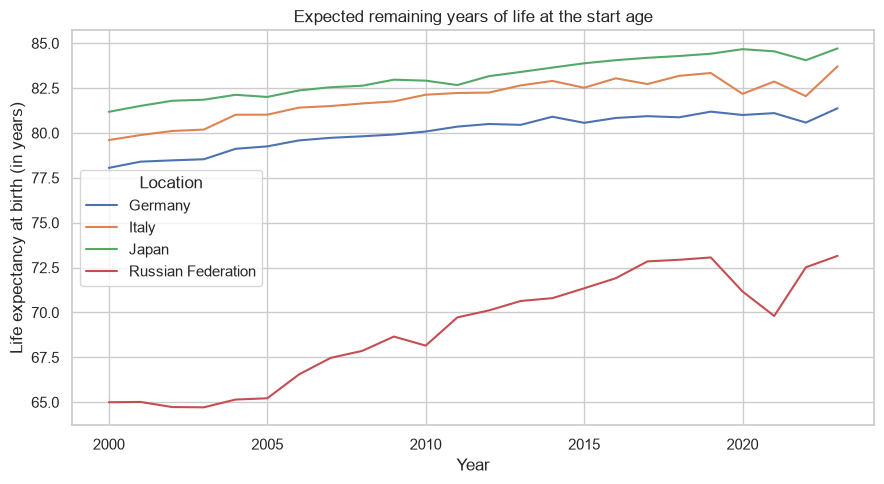

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=at_birth, x="Time", y="ex", hue="Location", estimator=None, errorbar=None, ax=ax)
ax.set(title="Expected remaining years of life at the start age", xlabel="Year", ylabel="Life expectancy at birth (in years)")
fig.tight_layout()
plt.show()

Japan had the highest period life expectancy at birth among these four countries in 2023. The Russian Federation rose from about 65 years in 2000 to 73 in 2023. A period table applies one period’s mortality rates throughout a hypothetical lifetime.

## D-03 · Survivorship by age

Select Italy (`ITA`), year 2023, and `Sex == "Total"` into `italy`.
Sort by `AgeGrpStart`. Plot `lx` against age. Start the y-axis at zero.

Describe the curve. Does `lx` mean the actual number of Italian residents at that age?
Explain why the final point at age 100 can be above zero even though the last
life-table interval is 100+.

Useful tools: `.eq()`, `.sort_values()`, `ax.plot(..., marker="o")`.

In [9]:
life["Location"].unique()

<StringArray>
['Germany', 'Italy', 'Japan', 'Russian Federation']
Length: 4, dtype: str

In [10]:
life.head()

,ISO3_code,Location,Time,Sex,AgeGrp,AgeGrpStart,AgeGrpSpan,mx,qx,px,lx,dx,Lx,Tx,ex,ax
0,DEU,Germany,2000,Female,0,0,1,0.003860,0.003847,0.996153,100000.000,384.724,99669.559,8099514.529,80.9951,0.141097
1,DEU,Germany,2000,Female,1-4,1,4,0.000213,0.000850,0.999150,99615.276,84.637,398249.489,7999844.970,80.3074,1.499757
2,DEU,Germany,2000,Female,5-9,5,5,0.000098,0.000490,0.999510,99530.638,48.758,497527.308,7601595.481,76.3744,2.418172
3,DEU,Germany,2000,Female,10-14,10,5,0.000110,0.000550,0.999450,99481.880,54.700,497280.596,7104068.173,71.4107,2.645228
4,DEU,Germany,2000,Female,15-19,15,5,0.000280,0.001399,0.998601,99427.180,139.101,496831.792,6606787.577,66.4485,2.813741


In [11]:
italy = life.loc[life["Location"].eq("Italy") & life["Time"].eq(2023) & life["Sex"].eq("Total")].sort_values("AgeGrpStart")
italy.head()

,ISO3_code,Location,Time,Sex,AgeGrp,AgeGrpStart,AgeGrpSpan,mx,qx,px,lx,dx,Lx,Tx,ex,ax
3146,ITA,Italy,2023,Total,0,0,1,0.002248,0.002244,0.997756,100000.000,224.385,99808.107,8371570.217,83.7157,0.144804
3147,ITA,Italy,2023,Total,1-4,1,4,0.000102,0.000407,0.999593,99775.615,40.607,399009.730,8271762.110,82.9036,1.716390
3148,ITA,Italy,2023,Total,5-9,5,5,0.000049,0.000243,0.999757,99735.008,24.228,498617.377,7872752.381,78.9367,2.620018
3149,ITA,Italy,2023,Total,10-14,10,5,0.000064,0.000319,0.999681,99710.780,31.836,498476.022,7374135.004,73.9552,2.553844
3150,ITA,Italy,2023,Total,15-19,15,5,0.000169,0.000843,0.999157,99678.944,84.063,498214.380,6875658.982,68.9780,2.854737


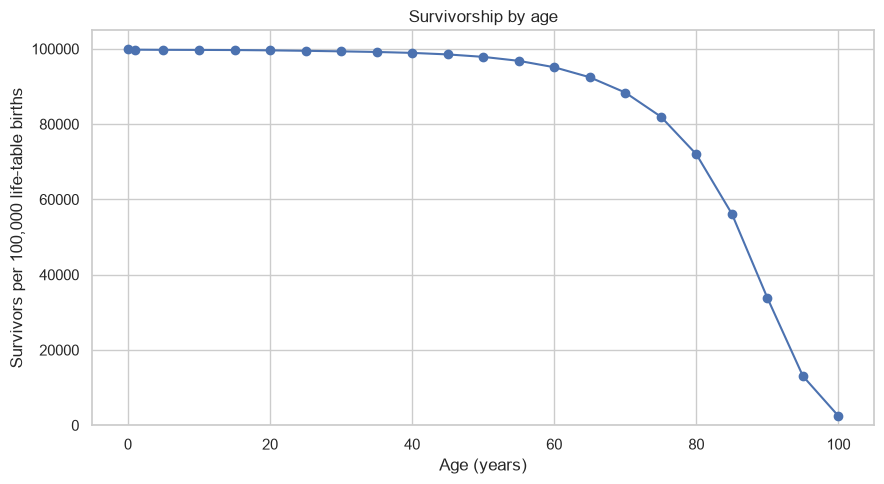

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(italy["AgeGrpStart"], italy["lx"], marker="o")
ax.set_ylim(bottom=0)
ax.set(title="Survivorship by age", xlabel="Age (years)", ylabel="Survivors per 100,000 life-table births")
fig.tight_layout()
plt.show()

The curve follows survivors from 100,000 hypothetical births as age increases. People who reach age 100 are counted at the start of the open-ended 100+ interval.

## D-04 · Calculate survival and remaining life expectancy

From `italy`, select the row whose `AgeGrpStart` is 65. Obtain a single row using `.iloc[0]`.
Calculate:

- survival to age 65 as `l65 / l0 × 100`, using the age-0 `lx` as `l0`;
- remaining life expectancy at 65 as `T65 / l65`;
- the difference between the calculated value and the published `ex`.

Explain the denominator and units in both calculations.
Is life expectancy at age 65 equal to life expectancy at birth minus 65?

In [13]:
italy.head()

,ISO3_code,Location,Time,Sex,AgeGrp,AgeGrpStart,AgeGrpSpan,mx,qx,px,lx,dx,Lx,Tx,ex,ax
3146,ITA,Italy,2023,Total,0,0,1,0.002248,0.002244,0.997756,100000.000,224.385,99808.107,8371570.217,83.7157,0.144804
3147,ITA,Italy,2023,Total,1-4,1,4,0.000102,0.000407,0.999593,99775.615,40.607,399009.730,8271762.110,82.9036,1.716390
3148,ITA,Italy,2023,Total,5-9,5,5,0.000049,0.000243,0.999757,99735.008,24.228,498617.377,7872752.381,78.9367,2.620018
3149,ITA,Italy,2023,Total,10-14,10,5,0.000064,0.000319,0.999681,99710.780,31.836,498476.022,7374135.004,73.9552,2.553844
3150,ITA,Italy,2023,Total,15-19,15,5,0.000169,0.000843,0.999157,99678.944,84.063,498214.380,6875658.982,68.9780,2.854737


In [14]:
row_65 = italy.loc[italy["AgeGrpStart"].eq(65)].iloc[0]

In [15]:
row_65

ISO3_code              ITA
Location             Italy
Time                  2023
Sex                  Total
AgeGrp               65-69
AgeGrpStart             65
AgeGrpSpan               5
mx                0.008984
qx                   0.044
px                   0.956
lx                92447.03
dx                4067.684
Lx              452782.287
Tx             1970101.551
ex                 21.3106
ax                2.676108
Name: 3160, dtype: object

In [16]:
l0 = italy.loc[italy["AgeGrpStart"].eq(0), "lx"].iloc[0]

In [17]:
survival_65 = row_65["lx"] / l0 * 100
survival_65

np.float64(92.44703)

In [18]:
remaining_years = row_65["Tx"] / row_65["lx"]
print("Remaining years at 65:", remaining_years)
print("Difference from published ex (years):", remaining_years - row_65["ex"])

Remaining years at 65: 21.31059863145414
Difference from published ex (years): -1.3685458597478828e-06


About 92.45% of the hypothetical cohort survive to age 65. Dividing their future person-years by the number of survivors gives 21.31 remaining years per survivor, matching the published value to its reported precision. Subtracting 65 from life expectancy at birth uses a different population.

## D-05 · An independent demographic comparison

Compare remaining life expectancy at age 65 in 2023 for all four countries,
keeping both sexes combined. Create a sorted horizontal bar chart with a zero baseline.

Write three sentences in the Markdown cell:
1. State one descriptive finding with the year and unit.
2. Explain what the indicator measures.
3. Name one limitation or one additional variable needed for a public-policy question.

Extension: compare Male and Female within Italy using the same year and age.
Do not add Total to an average of the sex-specific values.

In [19]:
row_65["ex"]

np.float64(21.3106)

In [20]:
life.head()

,ISO3_code,Location,Time,Sex,AgeGrp,AgeGrpStart,AgeGrpSpan,mx,qx,px,lx,dx,Lx,Tx,ex,ax
0,DEU,Germany,2000,Female,0,0,1,0.003860,0.003847,0.996153,100000.000,384.724,99669.559,8099514.529,80.9951,0.141097
1,DEU,Germany,2000,Female,1-4,1,4,0.000213,0.000850,0.999150,99615.276,84.637,398249.489,7999844.970,80.3074,1.499757
2,DEU,Germany,2000,Female,5-9,5,5,0.000098,0.000490,0.999510,99530.638,48.758,497527.308,7601595.481,76.3744,2.418172
3,DEU,Germany,2000,Female,10-14,10,5,0.000110,0.000550,0.999450,99481.880,54.700,497280.596,7104068.173,71.4107,2.645228
4,DEU,Germany,2000,Female,15-19,15,5,0.000280,0.001399,0.998601,99427.180,139.101,496831.792,6606787.577,66.4485,2.813741


In [21]:
age65 = life.loc[life["AgeGrpStart"].eq(65) & life["Time"].eq(2023) & life["Sex"].eq("Total")].sort_values("ex", ascending=False)
age65.head()

,ISO3_code,Location,Time,Sex,AgeGrp,AgeGrpStart,AgeGrpSpan,mx,qx,px,lx,dx,Lx,Tx,ex,ax
4744,JPN,Japan,2023,Total,65-69,65,5,0.008607,0.042198,0.957802,92324.178,3895.862,452627.172,2076623.861,22.4927,2.691469
3160,ITA,Italy,2023,Total,65-69,65,5,0.008984,0.044000,0.956000,92447.030,4067.684,452782.287,1970101.551,21.3106,2.676108
1576,DEU,Germany,2023,Total,65-69,65,5,0.013291,0.064425,0.935575,89258.001,5750.406,432656.189,1769045.201,19.8195,2.629069
6328,RUS,Russian Federation,2023,Total,65-69,65,5,0.023643,0.111845,0.888155,72822.483,8144.849,344487.498,1246970.268,17.1234,2.590512


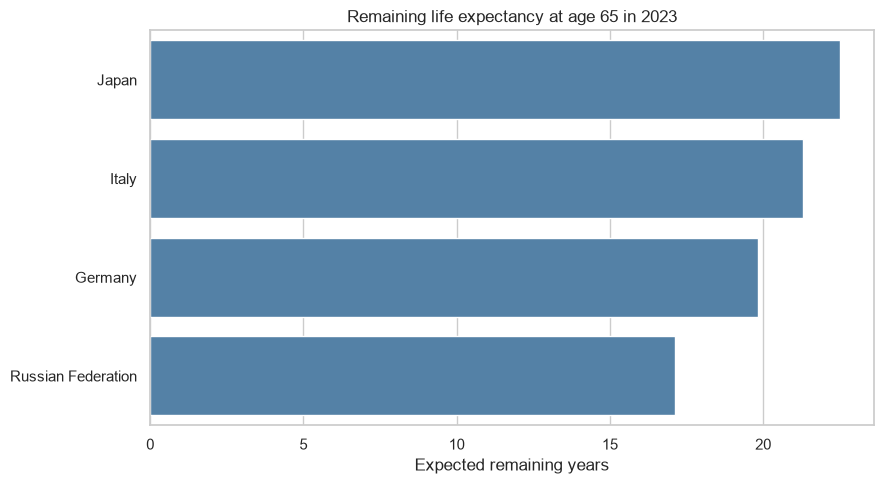

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=age65, errorbar=None, color="steelblue", x="ex", y="Location", ax=ax)
ax.set(title="Remaining life expectancy at age 65 in 2023", xlabel="Expected remaining years", ylabel="")
ax.set_xlim(left=0)
fig.tight_layout()
plt.show()

In 2023, Japan had the highest remaining life expectancy at 65 in this comparison (22.49 years). This is the average remaining lifetime conditional on reaching 65 under period mortality rates. Planning care services would also require information on disability and the number of residents at each age. The optional comparison by sex is left for practice.